In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
df=pd.read_csv('k-mean.csv')
df.head()

,Customer_ID,Age,Annual_Income,Annual_Spending,Purchase_Frequency,Website_Visits
0,1,22.0,22000.0,1800.0,2.0,35.0
1,2,24.0,25000.0,2200.0,3.0,42.0
2,3,21.0,20000.0,1500.0,2.0,30.0
3,4,26.0,NaN,2500.0,4.0,48.0
4,5,23.0,24000.0,1900.0,2.0,38.0


In [3]:
df.isnull().sum()

Customer_ID           0
Age                   2
Annual_Income         2
Annual_Spending       2
Purchase_Frequency    2
Website_Visits        2
dtype: int64

In [6]:
df["Age"]=df["Age"].fillna(df["Age"].mean())
df["Annual_Income"]=df["Annual_Income"].fillna(df["Annual_Income"].mean())
df["Annual_Spending"]=df["Annual_Spending"].fillna(df["Annual_Spending"].median())
df["Purchase_Frequency"]=df["Purchase_Frequency"].fillna(df["Purchase_Frequency"].median())
df["Website_Visits"]=df["Website_Visits"].fillna(df["Website_Visits"].median())
df.isnull().sum()

Customer_ID           0
Age                   0
Annual_Income         0
Annual_Spending       0
Purchase_Frequency    0
Website_Visits        0
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         30 non-null     int64  
 1   Age                 30 non-null     float64
 2   Annual_Income       30 non-null     float64
 3   Annual_Spending     30 non-null     float64
 4   Purchase_Frequency  30 non-null     float64
 5   Website_Visits      30 non-null     float64
dtypes: float64(5), int64(1)
memory usage: 1.5 KB


In [8]:
features = [
    "Age",
    "Annual_Income",
    "Annual_Spending",
    "Purchase_Frequency",
    "Website_Visits"
]
X = df[features]

In [9]:
scaler = StandardScaler()
X = scaler.fit_transform(X)
X

array([[-1.47733629e+00, -1.37146758e+00, -1.25425833e+00,
        -1.51601829e+00, -1.89084343e+00],
       [-1.30675725e+00, -1.25568540e+00, -1.13648760e+00,
        -1.25612944e+00, -1.56077101e+00],
       [-1.56262580e+00, -1.44865571e+00, -1.34258638e+00,
        -1.51601829e+00, -2.12660944e+00],
       [-1.13617822e+00, -2.80808764e-16, -1.04815955e+00,
        -9.96240588e-01, -1.27785179e+00],
       [-1.39204677e+00, -1.29427946e+00, -1.22481565e+00,
        -1.51601829e+00, -1.74938382e+00],
       [-1.05088870e+00, -1.06271508e+00, -9.89274178e-01,
        -9.96240588e-01, -1.08923898e+00],
       [-1.22146773e+00, -1.17849727e+00, -1.10704491e+00,
        -1.25612944e+00,  1.36744288e-01],
       [-8.80309663e-01, -9.85526957e-01, -9.30388810e-01,
        -7.36351739e-01, -9.47779373e-01],
       [-7.09730628e-01, -7.53962581e-01, -7.53732707e-01,
        -7.36351739e-01, -6.17706954e-01],
       [-4.53862075e-01, -5.99586331e-01, -2.53207081e-01,
        -4.76462890e-01

## Elbow Method

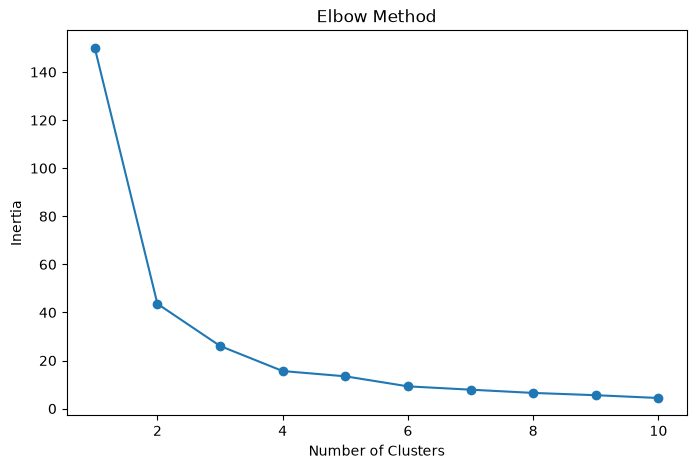

In [10]:
from sklearn.metrics import silhouette_score
inertia=[
]
for k in range(1,11):
    model=KMeans(n_clusters=k,random_state=42,n_init="auto")
    labels=model.fit_predict(X)
    inertia.append(model.inertia_)
    
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [12]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

labels = kmeans.fit_predict(X)

In [13]:
df["Cluster"] = labels

In [14]:
score = silhouette_score(
    X,
    labels
)

print("Silhouette Score:", score)


Silhouette Score: 0.4526002549145152


In [15]:
summary = df.groupby("Cluster")[features].mean()

print("\nCluster Summary:")
print(summary)



Cluster Summary:
               Age  Annual_Income  ...  Purchase_Frequency  Website_Visits
Cluster                            ...                                    
0        38.232143   49253.571429  ...            7.400000       75.400000
1        51.756494   87090.909091  ...           11.909091       96.272727
2        25.333333   30615.079365  ...            3.333333       48.888889

[3 rows x 5 columns]


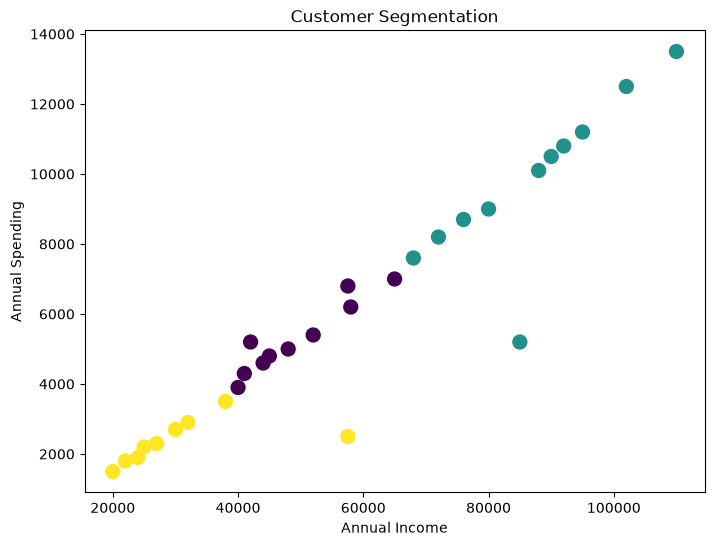

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Annual_Income"],
    df["Annual_Spending"],
    c=df["Cluster"],
    s=100
)

plt.xlabel("Annual Income")
plt.ylabel("Annual Spending")
plt.title("Customer Segmentation")

plt.show()